In [ ]:
#сккачиваю напрямую датасет
!kaggle datasets download -d maysee/mushrooms-classification-common-genuss-images

!unzip -q mushrooms-classification-common-genuss-images.zip -d data/

!ls data/

Dataset URL: https://www.kaggle.com/datasets/maysee/mushrooms-classification-common-genuss-images
License(s): copyright-authors
100% 1.85G/1.85G [00:19<00:00, 100MB/s]

mushrooms  Mushrooms


In [ ]:

!ls -R data/ | head -n 30

data/:
mushrooms
Mushrooms

data/mushrooms:
Mushrooms

data/mushrooms/Mushrooms:
Agaricus
Amanita
Boletus
Cortinarius
Entoloma
Hygrocybe
Lactarius
Russula
Suillus

data/mushrooms/Mushrooms/Agaricus:
000_ePQknW8cTp8.jpg
001_2jP9N_ipAo8.jpg
002_hNh3aQSH-ZM.jpg
003_4AurAO4Jil8.jpg
004_Syi3NxxviC0.jpg
005_sUqyy4Yb9VY.jpg
006_1_E6AXBJqn4.jpg
009_mrv34Sn4WiQ.jpg
010_Rk1D3EG856g.jpg
011_WtefvQHAs0w.jpg
012_i_TOGa08rRE.jpg


начинаю обучение...
лучшая модель сохранена с точностью: 0.6374
эпоха 1/5 | train Loss: 1.4890 | val Loss: 1.1287 | train Acc: 0.4938 | val Acc: 0.6374
лучшая модель сохранена с точностью: 0.6642
эпоха 2/5 | train Loss: 1.0534 | val Loss: 0.9791 | train Acc: 0.6500 | val Acc: 0.6642
лучшая модель сохранена с точностью: 0.6977
эпоха 3/5 | train Loss: 0.9349 | val Loss: 0.8840 | train Acc: 0.6844 | val Acc: 0.6977
лучшая модель сохранена с точностью: 0.6984
эпоха 4/5 | train Loss: 0.8753 | val Loss: 0.8420 | train Acc: 0.6954 | val Acc: 0.6984
лучшая модель сохранена с точностью: 0.7036
эпоха 5/5 | train Loss: 0.8218 | val Loss: 0.8244 | train Acc: 0.7256 | val Acc: 0.7036


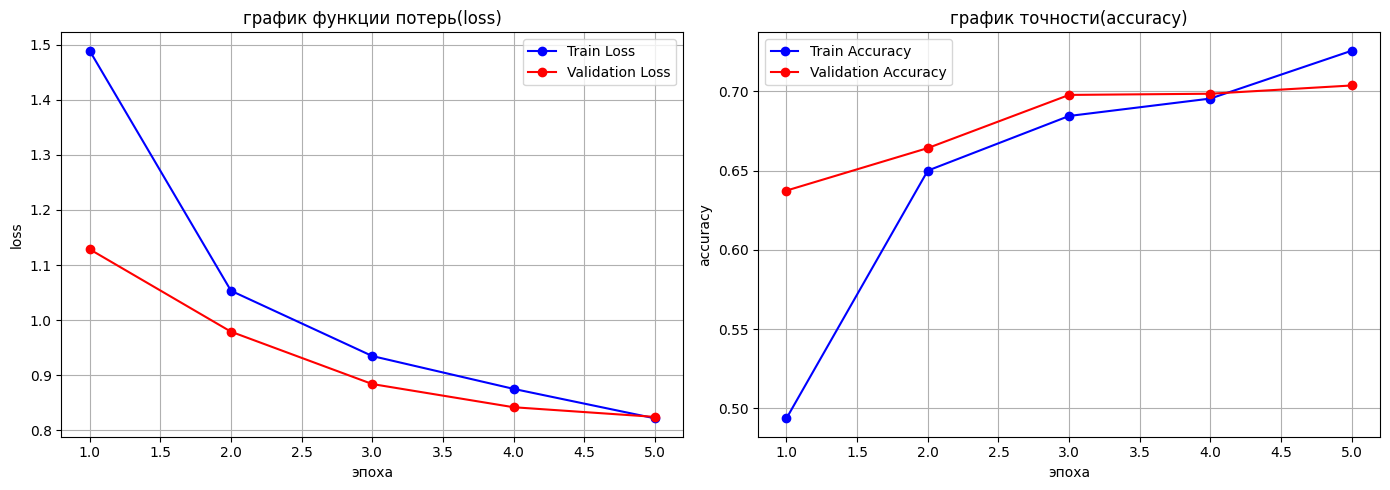

точность на тренировочной выборке: 0.7256
точность на валидационной выборке: 0.7036


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from PIL import ImageFile
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np

ImageFile.LOAD_TRUNCATED_IMAGES = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


data_dir = 'data/mushrooms/Mushrooms'
train_transforms = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transforms = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class SafeImageFolder(datasets.ImageFolder):
    def __getitem__(self, index):
        while True:
            try:
                path, target = self.samples[index]
                sample = self.loader(path)
                if self.transform is not None: sample = self.transform(sample)
                if self.target_transform is not None: target = self.target_transform(target)
                return sample, target
            except Exception:
                index = torch.randint(0, len(self.samples), (1,)).item()

full_dataset = SafeImageFolder(root=data_dir)
class_names = full_dataset.classes
num_classes = len(class_names)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])
train_dataset.dataset.transform = train_transforms
val_dataset.dataset.transform = val_transforms

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model.parameters(): param.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)


train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []

num_epochs = 5

print("начинаю обучение...")

best_val_acc = 0.0

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct, total = 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    train_loss_history.append(train_loss)
    train_acc_history.append(train_acc)

    model.eval()
    val_running_loss = 0.0
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = val_correct / val_total
    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)


    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_model.pth')
        print(f"лучшая модель сохранена с точностью: {val_acc:.4f}")

    print(f"эпоха {epoch+1}/{num_epochs} | train Loss: {train_loss:.4f} | val Loss: {val_loss:.4f} | train Acc: {train_acc:.4f} | val Acc: {val_acc:.4f}")


model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(14, 5))

#loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss_history, label='Train Loss', marker='o', color='blue')
plt.plot(epochs_range, val_loss_history, label='Validation Loss', marker='o', color='red')
plt.title('график функции потерь(loss)')
plt.xlabel('эпоха')
plt.ylabel('loss')
plt.legend()
plt.grid(True)

#accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc_history, label='Train Accuracy', marker='o', color='blue')
plt.plot(epochs_range, val_acc_history, label='Validation Accuracy', marker='o', color='red')
plt.title('график точности(accuracy)')
plt.xlabel('эпоха')
plt.ylabel('accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"точность на тренировочной выборке: {train_acc_history[-1]:.4f}")
print(f"точность на валидационной выборке: {val_acc_history[-1]:.4f}")

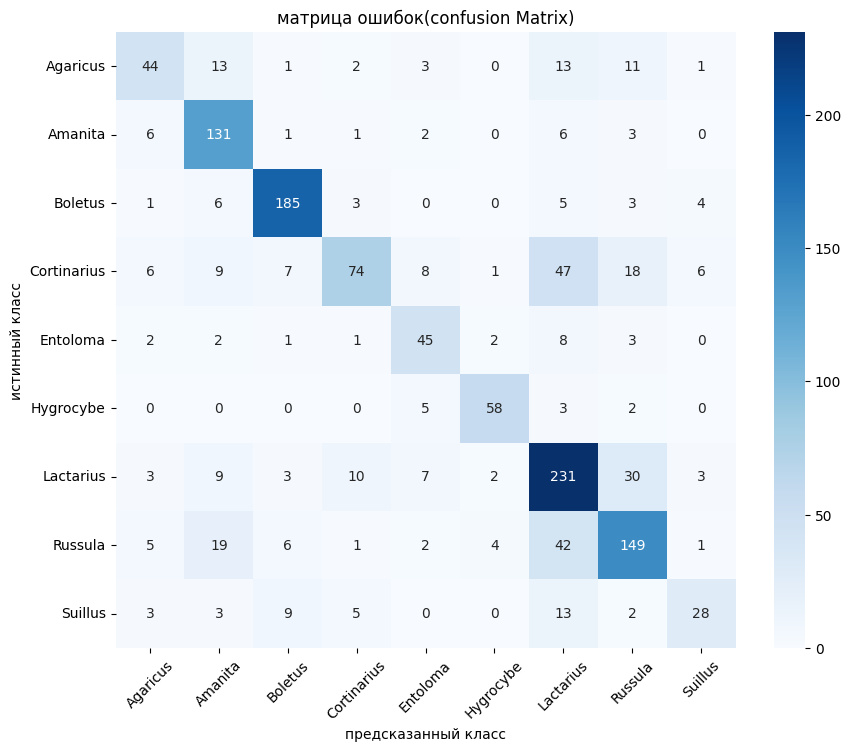

              precision    recall  f1-score   support

    Agaricus       0.63      0.50      0.56        88
     Amanita       0.68      0.87      0.77       150
     Boletus       0.87      0.89      0.88       207
 Cortinarius       0.76      0.42      0.54       176
    Entoloma       0.62      0.70      0.66        64
   Hygrocybe       0.87      0.85      0.86        68
   Lactarius       0.63      0.78      0.69       298
     Russula       0.67      0.65      0.66       229
     Suillus       0.65      0.44      0.53        63

    accuracy                           0.70      1343
   macro avg       0.71      0.68      0.68      1343
weighted avg       0.71      0.70      0.70      1343



In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('матрица ошибок(confusion Matrix)')
plt.ylabel('истинный класс')
plt.xlabel('предсказанный класс')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

print(classification_report(all_labels, all_preds, target_names=class_names))

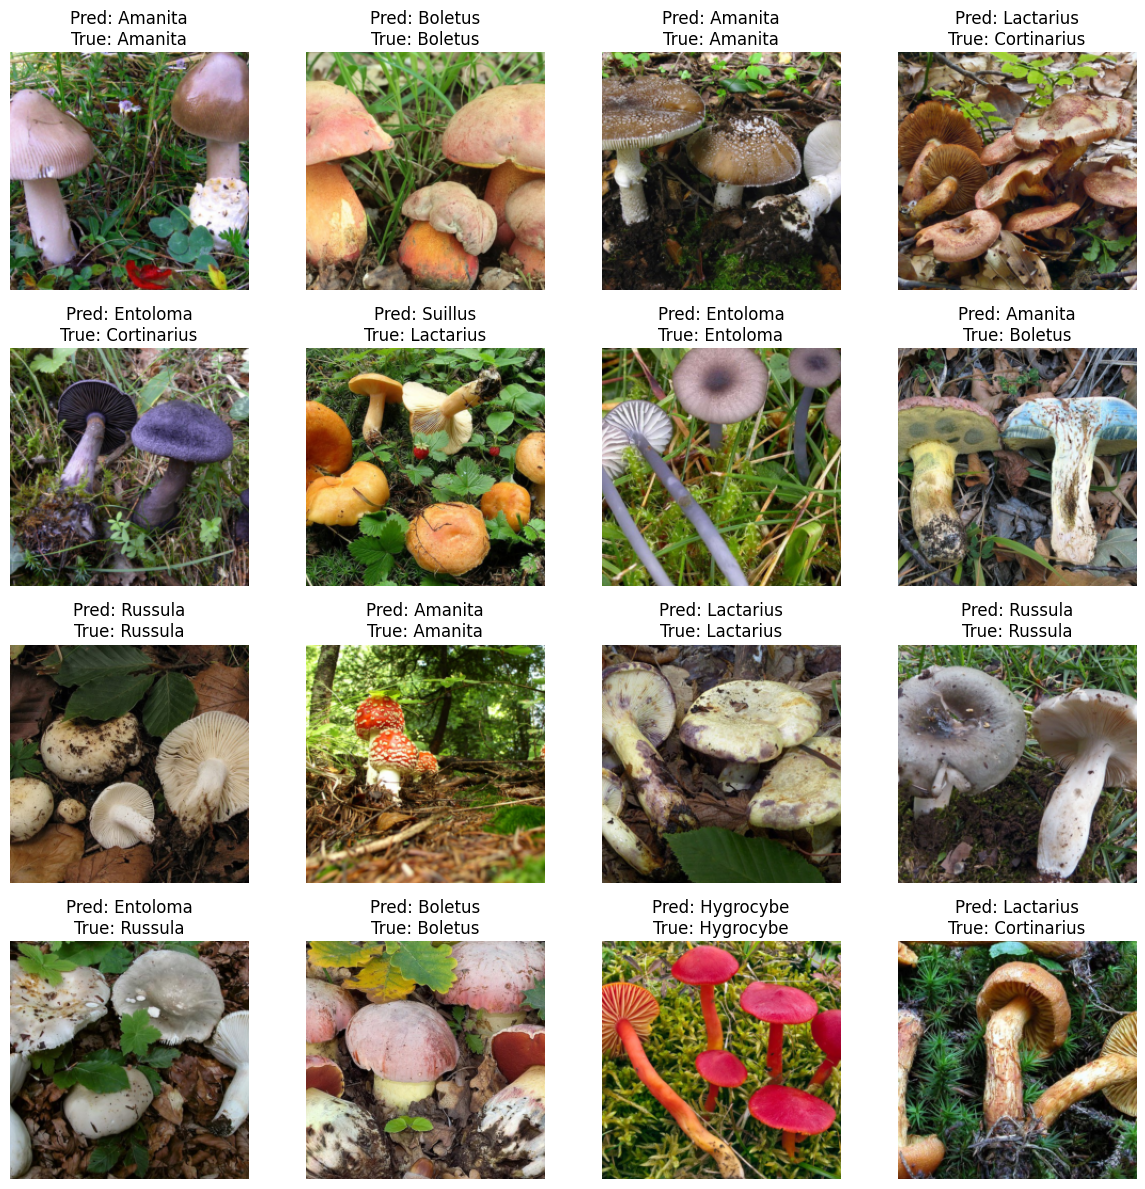

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torchvision

def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)

images, labels = next(iter(val_loader))
images, labels = images.to(device), labels.to(device)

model.eval()
with torch.no_grad():
    outputs = model(images)
    _, preds = torch.max(outputs, 1)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()
for i in range(16):
    img = images[i].cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)

    axes[i].imshow(img)
    axes[i].set_title(f"Pred: {class_names[preds[i]]}\nTrue: {class_names[labels[i]]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()